# 01 — EDA: Hyderabad hourly PM2.5

**Source:** Open-Meteo Air Quality API (CAMS global model estimates, ~0.4° grid) at 17.385 N, 78.487 E.
These are model estimates, not station measurements, so the series is smooth and has no gaps.

Questions this notebook answers before modelling:
1. What range and frequency does the data cover, and is anything missing?
2. Which seasonal cycles are there (daily, weekly, yearly)?
3. Do Diwali and winter visibly shift the level (drift we'll need to catch in Part 5)?
4. Is the series stationary, and which lags carry information?

Reads the output of the DVC `prepare` stage, so run `dvc repro` first.

In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.stattools import acf, adfuller

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/processed/pm25_hourly.parquet")
y = df["pm25"]

# Chart style: one blue for a single series, recessive grid and axes
BLUE, BLUE_LIGHT, INK, INK2 = "#2a78d6", "#86b6ef", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#d6d5d0",
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.8,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 2,
        "figure.dpi": 110,
    }
)

## 1. Coverage and data quality

In [2]:
summary = pd.Series(
    {
        "first hour": y.index.min(),
        "last hour": y.index.max(),
        "hours": len(y),
        "all steps exactly 1 hour": bool(
            (y.index.to_series().diff().dropna() == pd.Timedelta("1h")).all()
        ),
        "missing hours": int(df["is_missing"].sum()),
        "imputed hours": int(df["is_imputed"].sum()),
        "duplicate timestamps": int(y.index.duplicated().sum()),
    }
)
print(summary.to_string())
y.describe().round(1)

first hour                  2022-08-04 05:00:00
last hour                   2026-11-23 04:00:00
hours                                     37728
all steps exactly 1 hour                   True
missing hours                                 0
imputed hours                                 0
duplicate timestamps                          0


count    37728.0
mean        28.4
std         18.3
min          0.4
25%         13.5
50%         25.3
75%         39.7
max        138.3
Name: pm25, dtype: float64

## 2. The full series

Daily mean (blue) over the hourly values (light). Look for the yearly cycle and whether winters differ between years.

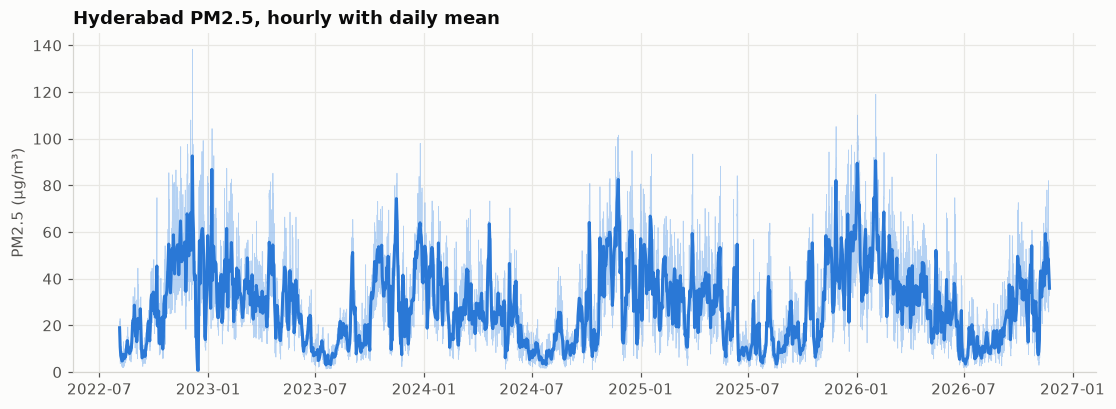

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, y, color=BLUE_LIGHT, linewidth=0.5, alpha=0.6)
ax.plot(y.resample("D").mean(), color=BLUE)
ax.set_title("Hyderabad PM2.5, hourly with daily mean")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_ylim(bottom=0)
plt.show()

## 3. Seasonal cycles

Three candidate seasons: hour of day (24), day of week (168 hours), and month of year.

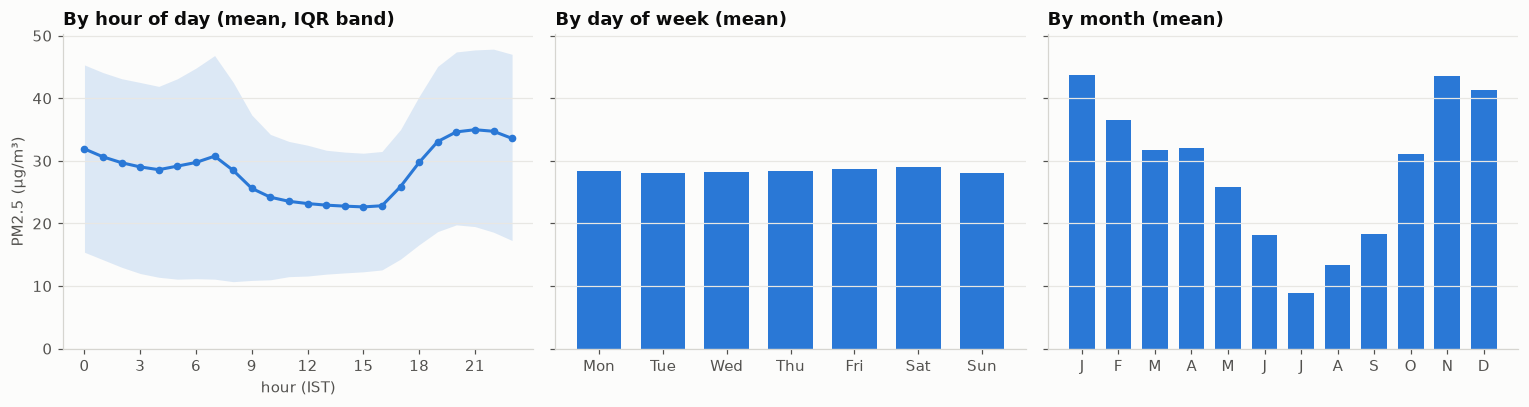

Hour-of-day swing: 12.3 µg/m³
Day-of-week swing: 0.9 µg/m³
Month swing:       34.8 µg/m³


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)

by_hour = y.groupby(y.index.hour)
axes[0].fill_between(
    range(24), by_hour.quantile(0.25), by_hour.quantile(0.75), color=BLUE, alpha=0.15, linewidth=0
)
axes[0].plot(range(24), by_hour.mean(), color=BLUE, marker="o", markersize=4)
axes[0].set_title("By hour of day (mean, IQR band)")
axes[0].set_xlabel("hour (IST)")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_ylabel("PM2.5 (µg/m³)")

dow = y.groupby(y.index.day_of_week).mean()
axes[1].bar(range(7), dow, color=BLUE, width=0.7)
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("By day of week (mean)")

mon = y.groupby(y.index.month).mean()
axes[2].bar(range(1, 13), mon, color=BLUE, width=0.7)
axes[2].set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[2].set_title("By month (mean)")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Hour-of-day swing: {by_hour.mean().max() - by_hour.mean().min():.1f} µg/m³")
print(f"Day-of-week swing: {dow.max() - dow.min():.1f} µg/m³")
print(f"Month swing:       {mon.max() - mon.min():.1f} µg/m³")

### Hour × month

Does the daily cycle change shape across the year? (Single-hue scale: darker = higher.)

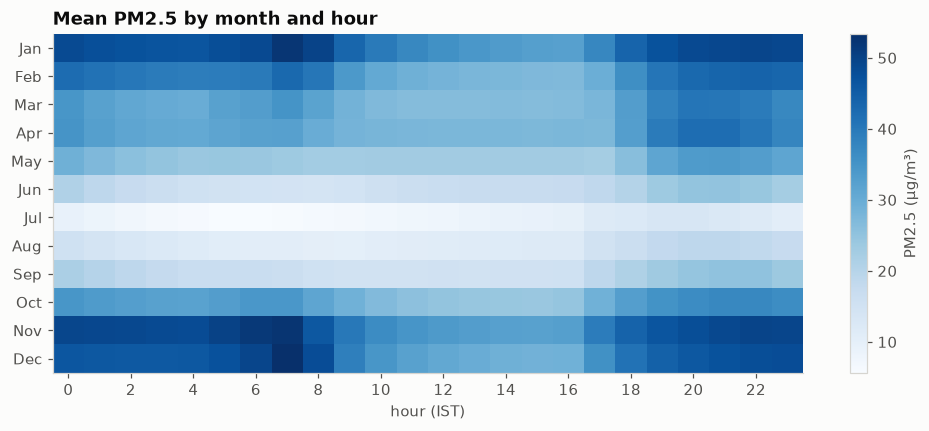

In [5]:
pivot = y.groupby([y.index.month, y.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(pivot, aspect="auto", cmap="Blues", origin="upper")
ax.set_yticks(
    range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour (IST)")
ax.set_title("Mean PM2.5 by month and hour")
ax.grid(False)
fig.colorbar(im, ax=ax, label="PM2.5 (µg/m³)")
plt.show()

## 4. Diwali and winter: drift we'll need to catch

Mean PM2.5 in the 7 days before vs. the 7 days after Diwali, per year.

In [6]:
rows = []
for year in sorted(set(y.index.year)):
    diwali = [d for d, n in holidays.India(years=year).items() if "Diwali" in n or "Deepavali" in n]
    if not diwali:
        continue
    d = pd.Timestamp(diwali[0])
    before, after = (
        y[d - pd.Timedelta(days=7) : d - pd.Timedelta(hours=1)],
        y[d : d + pd.Timedelta(days=7)],
    )
    if len(before) and len(after):
        rows.append(
            {
                "year": year,
                "diwali": d.date(),
                "mean_7d_before": before.mean(),
                "mean_7d_after": after.mean(),
            }
        )
diwali_df = pd.DataFrame(rows).set_index("year")
diwali_df["change_%"] = 100 * (diwali_df["mean_7d_after"] / diwali_df["mean_7d_before"] - 1)
diwali_df.round(1)

,diwali,mean_7d_before,mean_7d_after,change_%
year,,,,
2022,2022-10-24,28.7,43.4,51.0
2023,2023-11-12,27.5,57.8,110.0
2024,2024-10-31,47.2,46.9,-0.6
2025,2025-10-20,40.5,10.5,-74.0
2026,2026-11-08,17.4,39.1,124.3


In [7]:
season = pd.cut(
    y.index.month,
    bins=[0, 2, 5, 9, 12],
    labels=["Winter (Jan–Feb)", "Summer (Mar–May)", "Monsoon (Jun–Sep)", "Post-monsoon (Oct–Dec)"],
)
y.groupby(season, observed=True).agg(["mean", "std", "max"]).round(1)

,mean,std,max
Winter (Jan–Feb),40.2,17.4,119.0
Summer (Mar–May),29.8,12.8,93.4
Monsoon (Jun–Sep),14.8,10.2,84.1
Post-monsoon (Oct–Dec),38.3,19.5,138.3


## 5. Stationarity and autocorrelation

Which lags matter? Peaks at 24 and 168 justify the lag features in `params.yaml`.

ADF on the last year: statistic=-5.88, p=0.0000 -> stationary at 5%


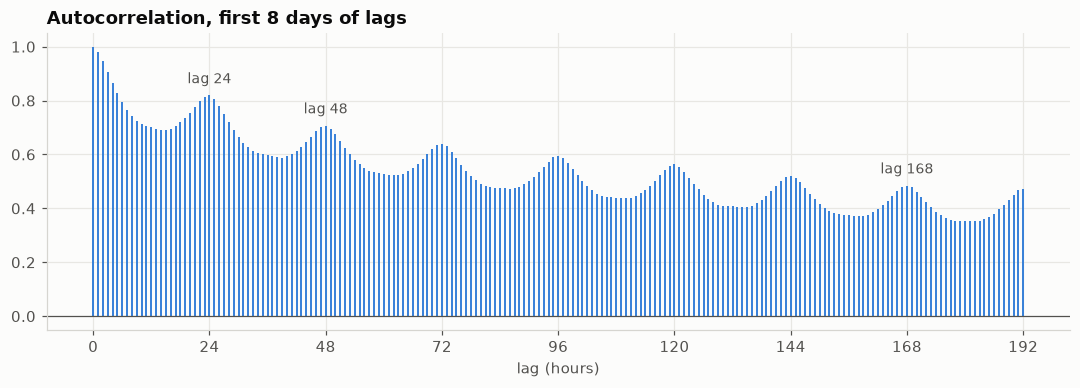

{1: 0.982, 2: 0.946, 3: 0.905, 6: 0.795, 12: 0.701, 24: 0.819, 48: 0.707, 168: 0.484}


In [8]:
adf_stat, p_value, *_ = adfuller(y.iloc[-24 * 365 :], autolag="AIC", result_object=False)
print(
    f"ADF on the last year: statistic={adf_stat:.2f}, p={p_value:.4f} "
    f"-> {'stationary' if p_value < 0.05 else 'NOT stationary'} at 5%"
)

lags = 24 * 8
r = acf(y, nlags=lags, fft=True)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.vlines(range(lags + 1), 0, r, color=BLUE, linewidth=1.2)
for lag in (24, 48, 168):
    ax.annotate(
        f"lag {lag}",
        (lag, r[lag]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color=INK2,
        fontsize=9,
    )
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(range(0, lags + 1, 24))
ax.set_xlabel("lag (hours)")
ax.set_title("Autocorrelation, first 8 days of lags")
plt.show()
print({lag: round(float(r[lag]), 3) for lag in (1, 2, 3, 6, 12, 24, 48, 168)})

## 6. Findings → decisions

Data through 23 Nov 2026 (37,728 hours).

- **Coverage:** 4 Aug 2022 to 23 Nov 2026, regular hourly, **0 missing, 0 duplicates**. The cleaning step is a safety net for now; it starts to matter if we switch to station data.
- **Yearly cycle is the biggest effect (34.8 µg/m³ swing):** July averages ~9, November–January ~42–44. Monsoon mean 14.8 vs winter 40.2. → `month` feature; walk-forward folds must not all sit in one season.
- **Daily cycle is clear (12.3 µg/m³ swing):** low around 15:00 (~23), evening peak 20:00–22:00 (~35), smaller morning bump ~07:00. The cycle is strongest in winter (heatmap). → `seasonal_period: 24`.
- **No weekly cycle (0.9 µg/m³ swing).** Expected for model estimates, which don't see weekday traffic well. → keep `lag_168` and `dayofweek` cheaply, but don't expect them to help.
- **Diwali is not a clean signal:** after Diwali PM2.5 rose +51%, +110% and +124% in 2022, 2023 and 2026, but was flat in 2024 and fell 74% in 2025 (likely rain). The October/November seasonal rise is the dependable drift; Diwali itself is noisy. → `is_holiday` stays, but don't oversell it.
- **Stationary** over the last year (ADF p < 0.001), so SARIMA needs no regular differencing (d = 0 to start).
- **Autocorrelation:** lag 1 = 0.98, lag 24 = 0.82 (higher than lag 12 = 0.70), lag 168 = 0.48. → the 24 h seasonal-naive baseline will be strong; lags 1–3, 24, 48 are the most useful features.
- **Watch out:** with lag 1 = 0.98, a model can look great on 1-hour-ahead and poorly at 24 h. Evaluate on the full 24-hour horizon (Phase 2).